# Week 11 · Machine learning 1: from data to prediction

**CMT124** · Thursday 17 December 2026

Last week you estimated a mean from a sample and asked how much to trust it. Machine learning takes the next step: it estimates a whole **relationship** between measurements and an outcome, and then uses it to **predict** outcomes it has not seen.

By the end of today you can describe a supervised learning problem by its features and target; split data into training and test sets; fit and use a regression model in scikit-learn; read residuals, MAE, RMSE and R²; recognise over-fitting; and choose which features a model really needs.

Today has two teaching parts and a guided lab: **Hour 1** from data to prediction · **Hour 2** improving a regression model · **Guided lab** predicting PM2.5, step by step.

## Setup

Run this cell first. It loads the libraries and defines `make_air_quality()`, which makes today's data. In Colab the code is hidden: we'll look inside it at the end of Hour 2. NumPy, pandas, Matplotlib and scikit-learn are already installed in Colab, and no files are needed.

In [ ]:
#@title Setup: run this cell first
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def make_air_quality(n=5000, seed=3622626236, temp_mean=20):
    """Synthetic daily records at one roadside site: weather, traffic and PM2.5 (µg/m³)."""
    rng = np.random.RandomState(seed)
    temperature = rng.normal(temp_mean, 5, n)            # °C
    humidity = rng.uniform(30, 90, n)                    # %
    wind_speed = rng.exponential(2, n)                   # m/s
    traffic_intensity = rng.uniform(0, 100, n)           # arbitrary units
    pm25 = (5 + 0.4 * traffic_intensity
            + 0.1 * traffic_intensity * (temperature - 20)
            + 0.3 * (30 - np.clip(wind_speed, 0, 30))
            + 0.1 * (humidity - 50)
            - 0.3 * (temperature - 20))
    noise = 0.5 * rng.normal(0, 10, n) + 0.5 * rng.normal(5, 5, n)
    return pd.DataFrame({"temperature": temperature, "humidity": humidity,
                         "wind_speed": wind_speed, "traffic_intensity": traffic_intensity,
                         "pm25": pm25 + noise})

## Hour 1 · From data to prediction

### From Week 10 to machine learning

In Week 10 you treated a measurement as a **random variable**: a typical value plus noise. You estimated the typical value (a mean) from a sample and put an interval around it.

A regression model does the same for a relationship. It assumes

$$\text{outcome} = f(\text{measurements}) + \text{noise}$$

and **estimates** $f$ from examples. The classic estimator is **least squares**: choose the line that makes the squared errors on the examples as small as possible. Machine learning adds one habit that matters more than any formula: we judge a model by how well it predicts **data it has not seen**.

### What machine learning means here

A model has adjustable numbers (parameters, $\theta$). Learning means repeating three things until the error stops falling: predict, measure the error on the training data, adjust $\theta$.

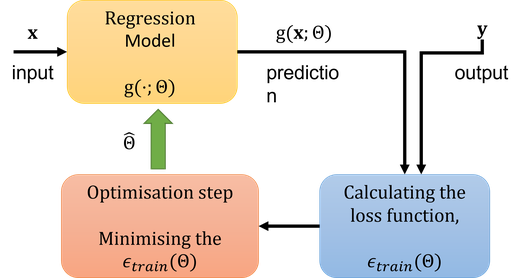

| | You have | The model learns | Example |
|---|---|---|---|
| **Supervised: regression** | features **X** and a numeric target **y** | $y \approx f(X)$ | PM2.5 in µg/m³ from weather and traffic |
| **Supervised: classification** | features **X** and a class label **y** | which class | land cover of a pixel: water, vegetation or urban |
| **Unsupervised** | features **X** only | groups or structure | clusters of similar monitoring sites |

Today is **supervised regression**. Week 12 is classification.

**Discuss:** we want to predict tomorrow's daily PM2.5 at a busy roadside monitor. What should our **target** be? Which measurements could be **features**, and which ones would we actually know in advance?

<details><summary>Answer</summary>

The target is the **daily mean PM2.5 concentration** (µg/m³): a number, so this is regression. Features must be things we know (or can forecast) **before** the day: weather forecasts (temperature, humidity, wind speed), expected traffic, day of the week, perhaps yesterday's PM2.5. Today's measured PM2.5 at a neighbouring station is a tempting feature, but it would not be available in advance: a feature that secretly contains the answer makes a model look better than it is.

</details>

### Today's data

`make_air_quality()` produces **5,000 days** of records at one roadside site: temperature (°C), relative humidity (%), wind speed (m/s), traffic intensity (arbitrary units) and the daily PM2.5 concentration (µg/m³).

These data are **synthetic**: a formula plus random noise, made for teaching. That has one big advantage: at the end of Hour 2 we can compare what the model learned with the truth. The patterns are illustrative, not measurements from a real city.

In [ ]:
air = make_air_quality()
print(air.shape)
air.head()

**Predict:** PM2.5 is the mass of fine particles in a cubic metre of air. What is the **smallest** value you expect to see in the `pm25` column?

In [ ]:
air["pm25"].describe().round(1)

### A data-quality problem: negative concentrations

A mass per cubic metre cannot be below zero, yet the minimum is about **−93 µg/m³**. Before any modelling, we find out how many rows are affected and what they look like.

In [ ]:
# ✍️ Type along: how many days have a negative PM2.5, and what are they like?

<details><summary>Code from class</summary>

```python
negative = air[air["pm25"] < 0]
print(len(negative), "days with negative PM2.5")
negative.describe().round(1)
```

</details>

**266 days** (about 5 %), and they are not tiny rounding errors near zero: half of them are below −11 µg/m³. Something went wrong in the way these records were made. (We'll see what at the end of Hour 2.)

We can't know the true values, so we **remove those rows** and work with the days we believe:

In [ ]:
air_clean = air[air["pm25"] >= 0]
print(len(air), "→", len(air_clean), "days")

<details><summary>Why not set the negative values to zero?</summary>

Setting them to zero (*clipping*) is reasonable when negative readings are small, for example an instrument reading −0.5 because of noise around zero. Here the values go down to −93, so a zero would be a **made-up value**: we would invent 266 perfectly clean days, and the model would learn from them. Removing the rows keeps only values we trust. The price: we now have **fewer examples of the conditions where the problem happened**, so the model will know less about them. Write that down as a limitation.

</details>

### Features, target and a fair test

We keep some days aside as a **test set**. The model learns only from the **training set**; then we predict the test days and compare with what really happened. That tells us how the model is likely to do on days it has never seen.

<img alt="4,734 days split into a training set (80 per cent) used to fit the model and a test set (20 per cent) used to predict and compare with the true values" src="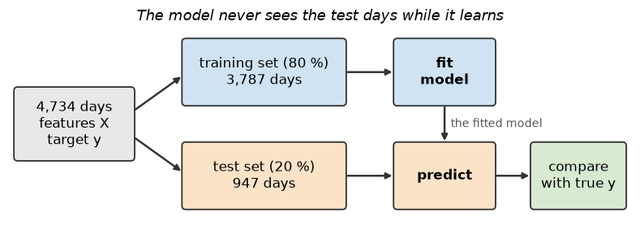">

In [ ]:
features = ["temperature", "humidity", "wind_speed", "traffic_intensity"]
X = air_clean[features]
y = air_clean["pm25"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

`train_test_split` shuffles the rows and keeps 20 % for testing; `random_state=42` makes the shuffle repeatable, so we all get the same split.

**Quick check:** why don't we judge the model on the days it was trained on?

* **A.** It would take too long.
* **B.** A model can memorise its training days, so its error there is too optimistic.
* **C.** The training days have no target values.

<details><summary>Answer</summary>

**B.** Judging a model on its training data is like marking students on exam questions they've already seen with the answers. The test set plays the part of new days.

</details>

### Fitting a first model

We start with **one feature**, traffic intensity, so the model is a straight line we can draw: $\widehat{\text{PM2.5}} = b_0 + b_1 \times \text{traffic}$.

Every scikit-learn model follows the same three steps: **create** it, **fit** it to the training data, **predict** new data.

In [ ]:
# ✍️ Type along: a linear regression of PM2.5 on traffic intensity; print the slope and intercept

<details><summary>Code from class</summary>

```python
line = LinearRegression()
line.fit(X_train[["traffic_intensity"]], y_train)      # X must be a table: note the double brackets
print("slope b1:", line.coef_.round(3), " intercept b0:", round(line.intercept_, 2))
```

</details>

In [ ]:
line = LinearRegression().fit(X_train[["traffic_intensity"]], y_train)
print("slope:", line.coef_.round(3), " intercept:", round(line.intercept_, 2))

Each extra unit of traffic adds about **0.53 µg/m³** to the predicted PM2.5; with no traffic at all, the line predicts about 14 µg/m³. Here is the line on top of the training data:

In [ ]:
xs = pd.DataFrame({"traffic_intensity": [0, 100]})
plt.scatter(X_train["traffic_intensity"], y_train, s=4, alpha=0.3, label="training days")
plt.plot(xs["traffic_intensity"], line.predict(xs), color="tab:red", lw=2, label="fitted line")
plt.xlabel("traffic intensity"); plt.ylabel("PM2.5 (µg/m³)"); plt.legend()
plt.title("More traffic, more PM2.5, but with a lot of scatter")
plt.show()

### Predictions and residuals

**Predict:** a test day has a traffic intensity of 80. Using the slope and intercept above, roughly what PM2.5 will the model predict?

In [ ]:
day = pd.DataFrame({"traffic_intensity": [80]})
line.predict(day)

14.4 + 0.531 × 80 ≈ **57 µg/m³**. For each test day, the **residual** is how far the prediction missed:

$$\text{residual} = \text{actual} - \text{predicted}$$

Positive residual: the model predicted too little; negative: too much.

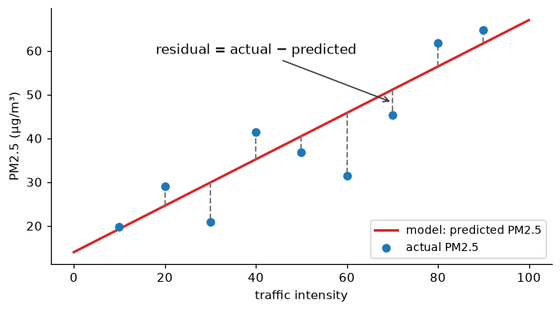

**Discuss:** what would a residual plot of a *perfect* model look like? And what would a residual plot of a *good, realistic* model look like?

In [ ]:
pred = line.predict(X_test[["traffic_intensity"]])
residuals = y_test - pred
plt.scatter(pred, residuals, s=5, alpha=0.4)
plt.axhline(0, color="black", lw=1)
plt.xlabel("predicted PM2.5 (µg/m³)"); plt.ylabel("residual (µg/m³)")
plt.show()

<details><summary>Answer</summary>

A perfect model has every residual **exactly 0**: all points on the horizontal line. Real data always contain noise, so a good realistic model has residuals **centred on 0, with no pattern** and a spread like the noise: a shapeless horizontal band. Here the band is wide (misses of ±40 µg/m³ are common), and the spread grows from left to right: one feature leaves a lot unexplained.

</details>

The **mean absolute error (MAE)** turns all the residuals into one number, in the units of the target: the average size of a miss.

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} \lvert y_i - \hat{y}_i \rvert$$

In [ ]:
mean_absolute_error(y_test, pred)

On a typical test day the traffic-only model misses by about **17 µg/m³**, when the median day is about 32 µg/m³. That is a weak model, but it is a **baseline**: every improvement today is measured against it.

**Your turn:** fit the same kind of model with **temperature** instead of traffic intensity, and compute its test MAE. Which single feature predicts PM2.5 better?

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
line_t = LinearRegression().fit(X_train[["temperature"]], y_train)
mean_absolute_error(y_test, line_t.predict(X_test[["temperature"]]))
```
About **14.7 µg/m³**: temperature alone predicts better than traffic alone (17.2). Surprised? Keep that question for Hour 2: the data will explain it.

</details>

### Takeaways: from data to prediction

* Supervised learning estimates $y \approx f(X)$ from examples: features **X**, target **y**. A numeric target means **regression**.
* Check the data before modelling. Impossible values (negative concentrations) are removed or fixed, and the decision is a limitation to remember.
* Fit on the **training** set, judge on the **test** set: create → `fit` → `predict`.
* A **residual** is actual − predicted. Good residuals are centred on zero with no pattern; **MAE** is their average size, in µg/m³.

## Hour 2 · Improving a regression model

### Recap

One feature at a time gave test MAEs of 17.2 (traffic) and 14.7 µg/m³ (temperature). This hour we use **several features**, try a **more flexible model**, meet the danger of **over-fitting**, and decide which features are worth keeping.

### More than one predictor

Multiple linear regression gives each feature its own slope:

$$\hat{y} = b_0 + b_1 x_1 + b_2 x_2 + \dots + b_p x_p$$

Each slope is the change in prediction for one unit of that feature **with the others held fixed**. The code is the same; only `X` changes.

In [ ]:
# ✍️ Type along: a linear regression on all four features; print one slope per feature

<details><summary>Code from class</summary>

```python
lin4 = LinearRegression().fit(X_train, y_train)
pd.Series(lin4.coef_, index=features).round(3)
```
About **+4.2 µg/m³ per °C** and **+0.46 per unit of traffic**; humidity (+0.10 per %) and wind speed (−0.26 per m/s) have small slopes.

</details>

### Three ways to score a regression

MAE is not the only score. Two more appear everywhere:

* **RMSE** (root mean squared error) $= \sqrt{\frac{1}{n}\sum (y_i - \hat{y}_i)^2}$: squaring makes big misses count more. It is **as sensitive to outliers as the MSE**, but it is back in the units of $y$ (µg/m³).
* **R²** $= 1 - \dfrac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$: the share of the target's variance (Week 10) that the model explains. 1 is perfect; 0 is no better than always predicting the mean.

A small helper prints all three:

In [ ]:
def scores(y_true, y_pred):
    return {"MAE": round(mean_absolute_error(y_true, y_pred), 2),
            "RMSE": round(mean_squared_error(y_true, y_pred) ** 0.5, 2),
            "R2": round(r2_score(y_true, y_pred), 3)}

lin4 = LinearRegression().fit(X_train, y_train)
scores(y_test, lin4.predict(X_test))

All four features: MAE **11.0 µg/m³**, R² **0.71**. Better than either feature alone, but still far from good.

### When a straight line isn't enough

**Before we run this:** if a linear model has captured everything, the residuals look like a shapeless band. Look for a **pattern**.

In [ ]:
plt.scatter(lin4.predict(X_test), y_test - lin4.predict(X_test), s=5, alpha=0.4)
plt.axhline(0, color="black", lw=1)
plt.xlabel("predicted PM2.5 (µg/m³)"); plt.ylabel("residual (µg/m³)")
plt.show()

The residuals **curve**: on the left and on the right they are mostly positive (the model predicts too **low**), in the middle mostly negative. Some predictions are even **below zero**, a concentration that cannot exist. The model is missing a shape that no straight line can follow.

A **random forest** is a flexible alternative: hundreds of decision trees, each a sequence of if/else splits on the features ("is traffic > 62? is temperature > 24?"), whose predictions are averaged. Trees can follow curves and **interactions** (one feature's effect depending on another) without being told.

**Predict:** will the random forest beat the linear model's R² of 0.71 by a little or by a lot?

In [ ]:
forest = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
forest.fit(X_train, y_train)
scores(y_test, forest.predict(X_test))

By a lot: MAE **5.0 µg/m³**, R² **0.94**. The relationship in these data is far from a straight line.

### Over-fitting: when a model learns the noise

A more flexible model can always fit the **training** data better. The danger is that it starts fitting the **noise**, which won't repeat on new days. Polynomial curves show it clearly: a 4th-order curve follows the trend; a 50th-order curve passes through every training point and is useless between them.

<img alt="Left: a 4th-order polynomial fits the data points smoothly. Right: a 50th-order polynomial passes through the points but swings wildly between them" src="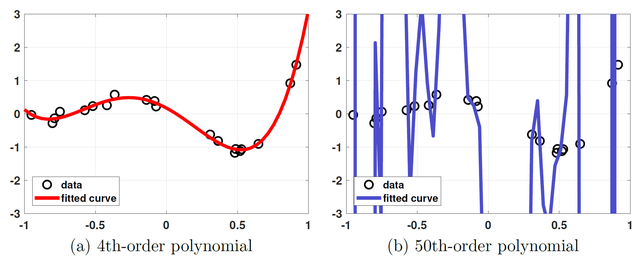">

Two kinds of error trade off. **Bias**: the model is too simple and misses the target systematically (like our straight line). **Variance**: the model is so flexible that it changes a lot with the particular training sample (like the 50th-order curve).

<img alt="Four dartboards: low bias and low variance (tight cluster on the centre), high bias and low variance (tight cluster off the centre), low bias and high variance (scattered around the centre), high bias and high variance (scattered off the centre)" src="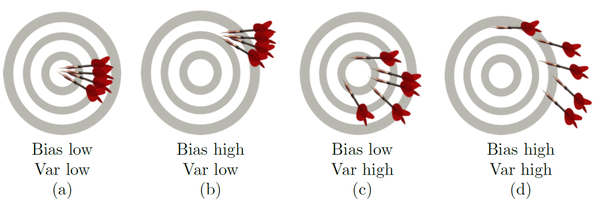">

We can watch it happen with a **single decision tree** whose maximum depth (number of if/else levels) we increase step by step.

**Predict:** as the tree gets deeper, what happens to the error on the **training** days? And on the **test** days?

In [ ]:
from sklearn.tree import DecisionTreeRegressor

depths = [1, 2, 3, 4, 6, 8, 10, 12, 15, 20]
train_rmse, test_rmse = [], []
for d in depths:
    tree = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_train, y_train)
    train_rmse.append(mean_squared_error(y_train, tree.predict(X_train)) ** 0.5)
    test_rmse.append(mean_squared_error(y_test, tree.predict(X_test)) ** 0.5)

plt.plot(depths, train_rmse, "o-", label="training days")
plt.plot(depths, test_rmse, "o-", label="test days")
plt.xlabel("maximum tree depth (model flexibility)"); plt.ylabel("RMSE (µg/m³)")
plt.title("Deeper trees: training error keeps falling, test error doesn't")
plt.legend(); plt.show()

On the left both errors are high: the tree is too simple (**bias**). Around depth 8 the test error is lowest. Beyond that the training error keeps falling towards zero while the test error **rises**: the tree is memorising noise (**variance**). This is why we always judge on the test set. A random forest averages many deep trees, and the averaging cancels much of their variance.

### Which features matter? Feature selection

So far we have given the model every feature. Choosing a **smaller set** of features is worth the effort because:
* every feature has to be **measured** (or forecast) for every new day, which costs money and can fail;
* a smaller model is easier to **explain** and to check;
* useless features add noise and can make over-fitting worse.

| Family | Idea | Example |
|---|---|---|
| **Filter** | score each feature on its own, before any model | correlation with the target; drop features that hardly vary |
| **Model-based** | ask a fitted model what it uses | permutation importance; LASSO (shrinks useless slopes to 0) |

**Predict:** which feature would you expect to matter most for PM2.5: temperature, humidity, wind speed or traffic intensity? Which least?

In [ ]:
X_train.join(y_train).corr()["pm25"].round(3)

The filter's view: temperature (0.73) and traffic (0.54) correlate with PM2.5; humidity and wind speed hardly at all. But correlation only sees **straight-line, one-at-a-time** relationships. A model-based check: **permutation importance** shuffles one feature's column in the test set, which breaks its link with the target, and measures how much the forest's R² drops. A big drop means the model relies on that feature.

In [ ]:
from sklearn.inspection import permutation_importance

result = permutation_importance(forest, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.Series(result.importances_mean, index=features).sort_values()
importance.plot.barh(xlabel="drop in R² when the feature is shuffled")
plt.show()

Both methods agree: **temperature** and **traffic intensity** carry almost all the information; shuffling humidity or wind speed costs the forest almost nothing.

The real test of a selection is to **refit with fewer features and compare on the test set**.

**Your turn:** fit a random forest on `["temperature", "traffic_intensity"]` only (same settings as `forest`), and compare its `scores` with the four-feature forest. How much accuracy did we lose?

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
selected = ["temperature", "traffic_intensity"]
forest2 = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
forest2.fit(X_train[selected], y_train)
scores(y_test, forest2.predict(X_test[selected]))
```
RMSE **7.0** instead of 6.4 µg/m³; R² **0.93** instead of 0.94. Half the features, almost all of the accuracy. Whether 0.6 µg/m³ is worth two more sensors is a judgement about cost and purpose, not a number the model can give you.

</details>

### Checking against the truth

Because the data are synthetic, we can open the box. This is the formula inside `make_air_quality()`, without the noise:

$$\text{PM2.5} = 5 + 0.4\,T_r + 0.1\,T_r\,(t - 20) + 0.3\,(30 - w) + 0.1\,(h - 50) - 0.3\,(t - 20)$$

with traffic $T_r$, temperature $t$ (°C), wind speed $w$ and humidity $h$, plus random noise with a standard deviation of about 5.6 µg/m³.

* **Temperature and traffic interact:** the term $0.1\,T_r\,(t-20)$ makes traffic add more PM2.5 on warm days and **less** on cold ones. A straight line can't represent that; a forest can. That's why the residuals curved and the forest won by so much.
* **Wind and humidity have real but small effects**, smaller than the noise. Feature selection judged their *usefulness*, not whether they exist.
* On cold, busy days the interaction term becomes large and negative: that is where the **negative PM2.5 values** came from.

**Discuss:** in many real cities, some of the worst PM2.5 episodes happen on **cold, still winter days**, when pollution is trapped near the ground. This dataset says the opposite. Would you trust a model trained on it to issue warnings in a real city, or in another year?

<details><summary>Answer</summary>

No. A model learns **the data it was given**, including its mistakes. It can only be as realistic as its training data, and it can only be trusted for conditions **like** its training data: same kind of site, same instruments, similar weather and traffic. Our cleaned data contain almost no cold, busy days, so predictions there are guesses. Before using a model somewhere new, test it on data from there. That is the thread we pick up in Week 12.

</details>

### Takeaways: improving a regression model

* More features help only if they carry information; a **more flexible model** (random forest) can capture curves and interactions a straight line can't.
* **RMSE** is in the target's units and punishes big misses; **R²** is the share of variance explained.
* **Over-fitting:** training error always falls with flexibility; test error falls, then rises. Judge on the test set.
* **Feature selection:** filters (correlation) are quick but see only straight-line, one-at-a-time links; model-based methods (permutation importance) ask the model. Always refit and compare.
* A model is only as trustworthy as its data, and only for conditions like its training data.

## Transition to the guided lab

**You now know** how to clean a target, split the data, fit linear regression and random forest models, read residuals and the three scores, and select features with correlation and permutation importance.

**The guided lab** (`W11_guided_lab_student.ipynb`, two hours) builds one PM2.5 prediction workflow from start to finish, step by step, with a checkpoint and a question at each step:
1. find the impossible PM2.5 values and look at **where** they occur;
2. clean the data and split it;
3. a baseline that knows nothing;
4. a linear model on two features;
5. what the residuals say;
6. all four features: linear regression and a random forest;
7. which features matter (permutation importance);
8. refit with the selected features and compare four models;
9. predictions for three new days, and what limits them.

## Week 11 takeaways

* A supervised learning problem is defined by its **target** and its **features**; choose features you will actually have when you need a prediction.
* Clean first: impossible values are removed (or fixed), and the decision becomes a limitation of the model.
* Fit on training data, judge on test data: residuals, MAE, RMSE, R².
* Flexible models capture more, but can over-fit; feature selection keeps the information and drops the cost.

## Where next

**Week 12 · Machine learning 2** (Thursday 7 January 2027). The same data and the same workflow, with a different question: instead of *how much* PM2.5, *is this a high-pollution day?* That target is a **class**, so the model becomes a **classifier**, and we will need new ways to judge it: when the class we care about is rare, accuracy alone can fool you. We'll also train a classifier on the satellite pixels from Week 7.

Before Week 12: rerun this notebook top to bottom and finish any *Your turn* you skipped.

## Optional: explore after class

None of this is needed in Week 12.

**Cross-validation.** One train/test split gives one score per model, and a different split would give a slightly different one. **5-fold cross-validation** splits the training data into five parts, trains on four and scores on the fifth, five times, and reports all five scores. The spread tells you how much a score depends on the split.

In [ ]:
from sklearn.model_selection import cross_val_score

cv = cross_val_score(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
                     X_train[["temperature", "traffic_intensity"]], y_train, cv=5, scoring="r2")
print(cv.round(3), "mean:", cv.mean().round(3))

**LASSO.** A linear regression with a penalty that pushes small slopes towards **exactly zero**, so it selects features while it fits. `LassoCV` chooses the strength of the penalty by cross-validation. A feature is kept when its coefficient is clearly non-zero, **positive or negative**.

In [ ]:
from sklearn.linear_model import LassoCV

lasso = LassoCV(random_state=42).fit(X_train, y_train)
pd.Series(lasso.coef_, index=features).round(3)

LASSO keeps all four here: humidity and wind speed get small but non-zero slopes, because their effects are real (see *Checking against the truth*). Selection methods answer different questions: "is it there?" versus "is it worth measuring?".

**Feature engineering.** The forest found the temperature × traffic interaction on its own. A linear model can use it too, if we **make it a feature**. Add a column `temp_x_traffic = temperature * traffic_intensity` to copies of `X_train` and `X_test`, fit `LinearRegression` on temperature, traffic and the new column, and compare its `scores` with the forest. (A hint at the result: one good feature can beat a much more complex model.)

<details><summary>Code</summary>

```python
X_tr = X_train[["temperature", "traffic_intensity"]].copy()
X_te = X_test[["temperature", "traffic_intensity"]].copy()
X_tr["temp_x_traffic"] = X_tr["temperature"] * X_tr["traffic_intensity"]
X_te["temp_x_traffic"] = X_te["temperature"] * X_te["traffic_intensity"]
lin_int = LinearRegression().fit(X_tr, y_train)
scores(y_test, lin_int.predict(X_te))        # RMSE about 6.0, R² about 0.95
```

</details>

## Credits

The air-quality data are synthetic, generated by the code in the Setup cell for this course.